# Regularised reconstruction with FISTA and ADMM

Reconstruct a known 3D sample from noisy projections, compare unregularised least squares with total variation (TV), and inspect the objective and ADMM residuals. All data are generated here with a fixed random seed.

Run this notebook after [synthetic 3D reconstruction](synthetic_3d.ipynb). It requires the current ToMoBAR API, NumPy, Matplotlib, CuPy, ASTRA and a working CUDA GPU; no external datasets or TomoPhantom are needed. See the [installation guide](../getting_started/installation.rst). Documentation displays the saved outputs without executing cells.

We use **full-data updates for both methods** (`num_subsets=1`) and isotropic 3D PD-TV. ADMM uses its CG data solver. This is a teaching comparison, not a runtime benchmark: an ADMM outer iteration contains several CG steps and costs more projection work than a FISTA iteration.

In [1]:
%matplotlib inline

from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import subprocess

import cupy as cp
import matplotlib.pyplot as plt
import numpy as np
import tomobar

from tomobar.geometry import Parallel3DGeometry, Volume3DGeometry
from tomobar.options import DataFidelity, Regularisation
from tomobar.reconstruction.iterative import IterativeReconstructor

# Record the environment used for the saved results.
print("Executed (UTC):", datetime.now(timezone.utc).isoformat(timespec="seconds"))
for package in ("tomobar", "numpy", "cupy", "astra-toolbox", "matplotlib"):
    print(f"{package}: {version(package)}")
source_root = Path(tomobar.__file__).resolve().parent.parent
if (source_root / ".git").exists():
    revision = subprocess.check_output(
        ["git", "-C", str(source_root), "rev-parse", "--short", "HEAD"], text=True
    ).strip()
    print("Checkout revision:", revision, "(local edits may be present)")
device_index = 0
properties = cp.cuda.runtime.getDeviceProperties(device_index)
gpu_name = properties["name"]
print("GPU:", gpu_name.decode() if isinstance(gpu_name, bytes) else gpu_name)
print("CUDA runtime:", cp.cuda.runtime.runtimeGetVersion())

Executed (UTC): 2026-11-18T22:01:00+00:00
tomobar: 2026.4.0.0
numpy: 2.4.6
cupy: 14.2.0
astra-toolbox: 2.5.0
matplotlib: 3.11.1
Checkout revision: d170474 (local edits may be present)
GPU: NVIDIA GeForce RTX 4060
CUDA runtime: 13020


## 1. Create a sample and noisy measurements

The volume has shape `(z, y, x) = (16, 48, 48)` and unit voxel spacing. The detector covers the whole sample. Angles span a half-turn, excluding the duplicate endpoint.

Gaussian noise is added directly to simulated **line integrals**, with standard deviation 2% of their peak. LS is appropriate for this simplified constant-variance model. These measurements are not raw transmission counts: no flat-field correction or negative logarithm is needed.

Projection shape (detY, angles, detX): (16, 60, 68)
Noise standard deviation: 0.4005


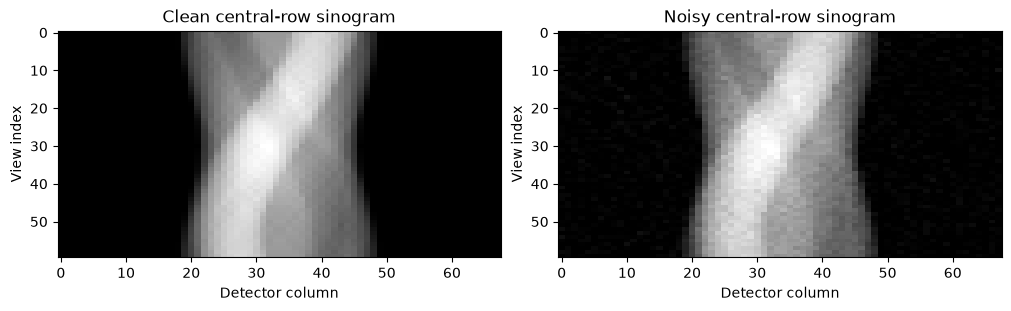

In [2]:
shape = (16, 48, 48)
coordinates = [np.arange(n, dtype=np.float32) - (n - 1) / 2 for n in shape]
z, y, x = np.meshgrid(*coordinates, indexing="ij")
phantom = np.zeros(shape, dtype=np.float32)
phantom[(x / 15) ** 2 + (y / 12) ** 2 + (z / 6) ** 2 <= 1] = 0.5
phantom[((x - 7) / 5) ** 2 + ((y + 3) / 6) ** 2 + (z / 4) ** 2 <= 1] = 1.0
phantom[((x + 7) / 3) ** 2 + ((y - 3) / 4) ** 2 + (z / 3) ** 2 <= 1] = 0.2

grid = Volume3DGeometry(shape=shape)
scan = Parallel3DGeometry.tomography(
    angles=np.linspace(0, np.pi, 60, endpoint=False),
    detector_shape=(shape[0], 68),
)
with IterativeReconstructor(
    projection_geometry=scan, volume_geometry=grid, device_index=device_index
) as rec:
    clean = cp.asnumpy(rec.forward(phantom))

rng = np.random.default_rng(42)
noise_std = 0.02 * float(clean.max())
projections = clean + rng.normal(0, noise_std, clean.shape).astype(np.float32)
print("Projection shape (detY, angles, detX):", projections.shape)
print(f"Noise standard deviation: {noise_std:.4f}")

figure, axes = plt.subplots(1, 2, figsize=(10, 3), constrained_layout=True)
for axis, data, title in zip(axes, (clean, projections), ("Clean", "Noisy")):
    axis.imshow(
        data[shape[0] // 2], cmap="gray", aspect="auto", vmin=0, vmax=clean.max()
    )
    axis.set_title(title + " central-row sinogram")
    axis.set_xlabel("Detector column")
    axis.set_ylabel("View index")
plt.show()

## 2. Solve the same TV-regularised objective

For nonnegative images, both regularised methods target

$$
\frac{1}{2}\|Ax-b\|_2^2 + \lambda\,\mathrm{TV}(x),\qquad x\geq0.
$$

`strength` is the coefficient $\lambda$ in this objective. ToMoBAR handles the internal FISTA step-size and ADMM `rho` scaling; pass the **same strength** to compare the same model. `rho` controls ADMM's splitting, not the TV weight.

We compare FISTA without TV, FISTA with strengths 1 and 10, and ADMM at strength 1. Each starts from zeros and runs 150 outer iterations. `Regularisation.iterations=50` controls the inner TV proximal solve, separately from the outer iteration budget. Increasing it improves proximal accuracy at additional cost.

The continuation interface retains energy histories and ADMM residuals. We omit stopping tolerances to use a fixed budget, so reaching the last iteration does not certify convergence. Masking is disabled when extracting images so metrics and energy refer to the full working volume.

In [3]:
outer_iterations = 150
strengths = (0.0, 1.0, 10.0)
selected_strength = 1.0
fidelity = DataFidelity(method="LS")
images, energies, energy_iterations = {}, {}, {}

with IterativeReconstructor(
    projection_geometry=scan,
    volume_geometry=grid,
    device_index=device_index,
    num_subsets=1,
) as rec:
    # Reuse one full-data estimate for all FISTA runs; CG needs no estimate.
    lipschitz = rec.powermethod(full_data=True)
    for strength in strengths:
        regularisation = (
            None
            if strength == 0
            else Regularisation(
                method="PD_TV", strength=strength, iterations=50, tv_type=0
            )
        )
        state = rec.initialise_solver(
            "FISTA",
            projections,
            fidelity=fidelity,
            regularisation=regularisation,
            nonnegativity=True,
            lipschitz_constant=lipschitz,
            return_energy=True,
        )
        rec.run(state, iterations=outer_iterations)
        label = f"FISTA, lambda={strength:g}"
        images[label] = cp.asnumpy(rec.solver_image(state, recon_mask_radius=None))
        energies[label] = state.energy.copy()
        energy_iterations[label] = state.energy_iterations.copy()

    state = rec.initialise_solver(
        "ADMM",
        projections,
        fidelity=fidelity,
        regularisation=Regularisation(
            method="PD_TV", strength=selected_strength, iterations=50, tv_type=0
        ),
        data_solver="cg",
        cg_iterations=5,
        cg_tolerance=1e-4,
        rho=10.0,
        relaxation=1.0,
        nonnegativity=True,
        return_energy=True,
    )
    rec.run(state, iterations=outer_iterations)
    label = f"ADMM-CG, lambda={selected_strength:g}"
    images[label] = cp.asnumpy(rec.solver_image(state, recon_mask_radius=None))
    energies[label] = state.energy.copy()
    energy_iterations[label] = state.energy_iterations.copy()
    residuals = state.residuals
    print("ADMM outer iterations:", state.iteration)
    print("Total inner CG iterations:", int(residuals["cg_iterations"].sum()))

ADMM outer iterations: 150
Total inner CG iterations: 750


## 3. Inspect detail, noise and regularisation strength

All slices share the same intensity range. The second row shows absolute error against the known sample on a common scale. RMSE is computed over the **entire volume**, including its background.

TV favours piecewise-constant regions. Too little leaves noise; too much can remove small features and bias intensities. The strengths below are specific to this data scale, geometry and noise level. Ground truth is available here to illustrate tuning; for experimental data, inspect features and residuals and use suitable validation data.

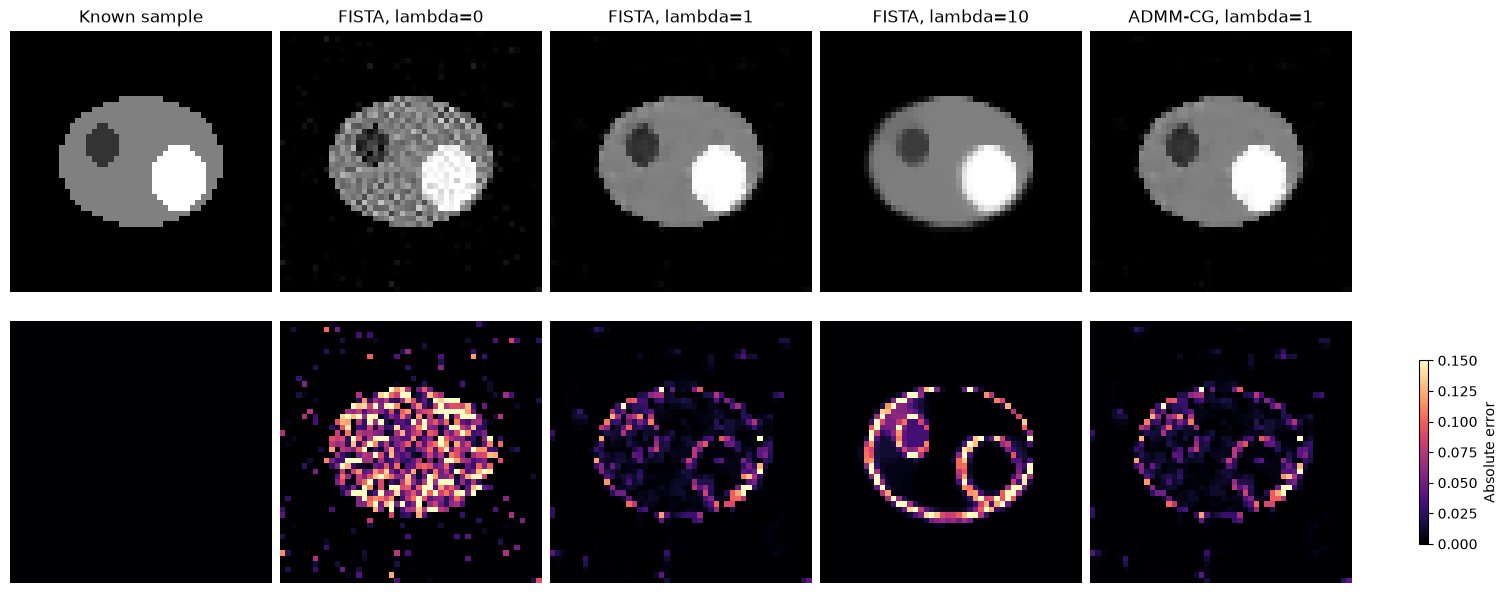

Reconstruction              Full-volume RMSE
FISTA, lambda=0                      0.03845
FISTA, lambda=1                      0.01526
FISTA, lambda=10                     0.02735
ADMM-CG, lambda=1                    0.01530


In [4]:
comparison = {"Known sample": phantom, **images}
figure, axes = plt.subplots(
    2, len(comparison), figsize=(15, 6), constrained_layout=True
)
for column, (label, image) in enumerate(comparison.items()):
    axes[0, column].imshow(
        image[shape[0] // 2], cmap="gray", vmin=0, vmax=1, origin="lower"
    )
    axes[0, column].set_title(label)
    error_plot = axes[1, column].imshow(
        np.abs(image - phantom)[shape[0] // 2],
        cmap="magma",
        vmin=0,
        vmax=0.15,
        origin="lower",
    )
    for axis in axes[:, column]:
        axis.set_axis_off()
figure.colorbar(error_plot, ax=axes[1, :], shrink=0.65, label="Absolute error")
plt.show()

print(f"{'Reconstruction':<25} {'Full-volume RMSE':>18}")
for label, image in images.items():
    rmse = float(np.sqrt(np.mean((image - phantom) ** 2)))
    print(f"{label:<25} {rmse:18.5f}")

## 4. Read the diagnostics

Only the FISTA and ADMM traces with **strength 1** are compared below: objective values for different strengths describe different optimisation problems. Energy is sampled at the initial image and after each outer iteration, and each evaluation adds a full forward projection.

ADMM's primal residual measures agreement between its data and regularised images; its dual residual measures the scaled image change; stationarity checks the inexact data solve. Their magnitudes have different meanings, so they need not coincide. These raw traces illustrate progress; formal stopping requires the configured absolute and relative thresholds. Accelerated FISTA energy need not decrease at every iteration. Equal iteration counts do not imply equal computation time.

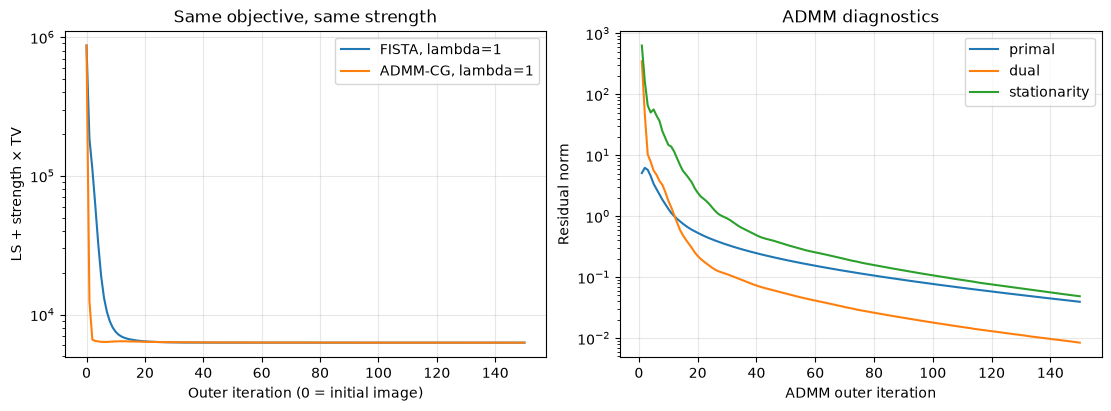

FISTA, lambda=1: initial energy=869762.272, final=6274.371
ADMM-CG, lambda=1: initial energy=869762.272, final=6274.921


In [5]:
figure, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for label in ("FISTA, lambda=1", "ADMM-CG, lambda=1"):
    axes[0].semilogy(energy_iterations[label], energies[label], label=label)
axes[0].set_xlabel("Outer iteration (0 = initial image)")
axes[0].set_ylabel("LS + strength × TV")
axes[0].set_title("Same objective, same strength")
axes[0].legend()
for key in ("primal", "dual", "stationarity"):
    axes[1].semilogy(residuals["iteration"], residuals[key], label=key)
axes[1].set_xlabel("ADMM outer iteration")
axes[1].set_ylabel("Residual norm")
axes[1].set_title("ADMM diagnostics")
axes[1].legend()
for axis in axes:
    axis.grid(True, alpha=0.3)
plt.show()

for label in ("FISTA, lambda=1", "ADMM-CG, lambda=1"):
    print(
        f"{label}: initial energy={energies[label][0]:.3f}, final={energies[label][-1]:.3f}"
    )

## Next steps

* Change the noise level or strengths and rerun all reconstruction cells. Inspect both the small inclusion and homogeneous regions.
* Increase the outer or proximal iteration budgets to distinguish incomplete optimisation from regularisation bias.
* Learn about [regularisation settings](../howto/regularisation.rst), [energy monitoring](../howto/monitor_energy.rst), [continuing a solver](../howto/continue_solver.rst), and [ADMM stopping criteria](../concepts/admm.rst).
* For PWLS/SWLS, provide suitable weights and retune strength for the prepared, normalised data objective. See [solver configuration](../howto/configure_solvers.rst).